# Titanic: **классификация выживания пассажиров**

Задача — по данным о пассажире предсказать `Survived`: 1 — выжил, 0 — погиб.

План проекта:

1. **EDA** — изучить данные и найти признаки, связанные с выживанием.
2. **Подготовка данных** — создать признаки и настроить обработку пропусков и категорий.
3. **Модели** — сравнить Logistic Regression, Decision Tree, Random Forest, XGBoost, CatBoost и KNN.
4. **SHAP** — посмотреть, какие признаки влияют на предсказания лучшей модели на деревьях.
5. **Submission** — обучить выбранную модель на всех обучающих данных и сохранить прогнозы для Kaggle.

Все выводы и метрики ниже рассчитываются из CSV-файлов при запуске ноутбука. Никакие результаты не подставляются вручную.

## 0. Данные

| Файл | Что внутри |
|---|---|
| `train.csv` | 891 пассажир, есть целевая колонка `Survived`. На этих данных обучаем модель и проверяем её на отложенной части. |
| `test.csv` | 418 пассажиров без `Survived`. После выбора модели предсказываем для них ответы и сохраняем `submission.csv`. |

Основные колонки:

- `Pclass` — класс билета: 1, 2 или 3.
- `Sex` — пол.
- `Age` — возраст, есть пропуски.
- `SibSp` — количество братьев/сестёр и супругов на борту.
- `Parch` — количество родителей и детей на борту.
- `Fare` — стоимость билета.
- `Embarked` — порт посадки: C / Q / S.
- `Cabin` — номер каюты, пропусков много. В первой версии не используем.
- `Name` — из имени извлечём обращение (`Mr`, `Mrs`, `Miss`, `Master` и другие). Само имя в модель не передаём.
- `Ticket` — номер билета. В первой версии не используем.
- `PassengerId` — идентификатор, не признак для модели.

Положи `train.csv` и `test.csv` рядом с ноутбуком. Код также проверяет папку `data/`.

In [1]:
# Импорт библиотек и загрузка данных

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


def find_data_file(filename):
    """Ищет CSV рядом с ноутбуком или в папке data/."""
    candidates = [Path(filename), Path("data") / filename]
    for path in candidates:
        if path.exists():
            return path
    searched = ", ".join(str(path) for path in candidates)
    raise FileNotFoundError(
        f"Не найден {filename}. Положи файл рядом с ноутбуком или в data/. Искали: {searched}"
    )


train_path = find_data_file("train.csv")
test_path = find_data_file("test.csv")

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

# Простые проверки, чтобы сразу заметить не тот датасет.
required_train_columns = {"PassengerId", "Survived", "Pclass", "Name", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"}
required_test_columns = required_train_columns - {"Survived"}

assert required_train_columns.issubset(train.columns), "В train.csv не хватает обязательных колонок."
assert required_test_columns.issubset(test.columns), "В test.csv не хватает обязательных колонок."
assert "Survived" not in test.columns, "В test.csv не должно быть целевой колонки Survived."

print(f"Train: {train.shape}; Test: {test.shape}")
print(f"Файлы: {train_path} и {test_path}")

Train: (891, 12); Test: (418, 11)
Файлы: train.csv и test.csv


## 1. Первый взгляд


- `head()` — как выглядит первые пять строк. 
- `info()` — тип каждой колонки и сколько в ней непустых значений.
- `describe()` — минимум, среднее, медиана для чисел.
- `isna().sum()` — сколько пропусков.

In [2]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
train.isna().sum().sort_values(ascending=False)

Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

**Первые наблюдения:** в `Cabin` действительно очень много пропусков, поэтому в базовой версии уберём эту колонку. Это не означает, что она совсем бесполезна: позднее из неё можно извлечь палубу (первую букву каюты). `Age` не будем заполнять до разделения на train и validation — медианы будут рассчитываться внутри `Pipeline` только по обучающей части, чтобы не подглядывать в validation.

## 2. EDA

Цель картинок: увидеть, **от чего зависит выживание**, до того как модель это «узнает» сама. Потом SHAP должен примерно подтвердить те же признаки.

Минимальный набор, который стоит нарисовать:

1. Сколько людей выжило и сколько нет — баланс классов.
2. Выживание по категориям: `Sex`, `Pclass`, `Embarked`.
3. Числа: распределение `Age` и `Fare` отдельно для выживших и погибших.
4. Семья: `SibSp`, `Parch` (или сумма `SibSp + Parch`).
5. Корреляции числовых колонок — тепловая карта. Она не заменяет графики по полу: `Sex` туда не попадёт, пока это текст.

Как читать столбчатый график по категории: по оси X группа, по оси Y доля выживших в группе (`mean` по `Survived`, потому что 0/1). Если столбец сильно выше или ниже общей доли выживших — признак полезный.

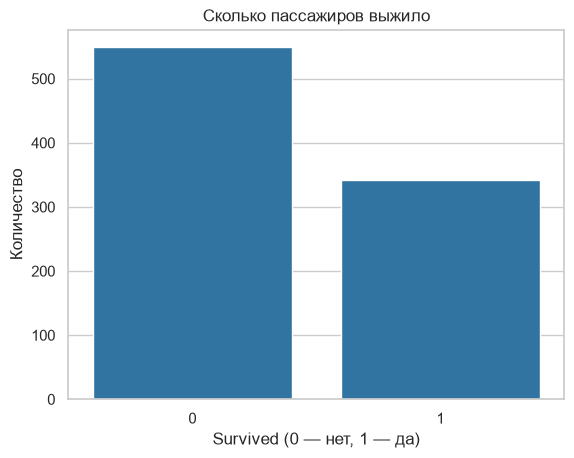

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

In [6]:
sns.countplot(data=train, x="Survived", color="tab:blue")
plt.title("Сколько пассажиров выжило")
plt.xlabel("Survived (0 — нет, 1 — да)")
plt.ylabel("Количество")
plt.show()

train["Survived"].value_counts(normalize=True)

Доля погибших — около 62%, поэтому простая модель, которая всегда отвечает `0`, уже получит accuracy около 0.62. Это **baseline**, с которым нужно сравнивать остальные модели. Но accuracy не рассказывает всю историю: поэтому ниже также считаем F1 и ROC-AUC.

### 2.2. Категории и выживание

Сравним долю выживших по `Sex`, `Pclass` и `Embarked`. Для бинарной колонки `Survived` среднее значение равно доле пассажиров, у которых `Survived = 1`. Рядом выведем таблицы с этой долей.

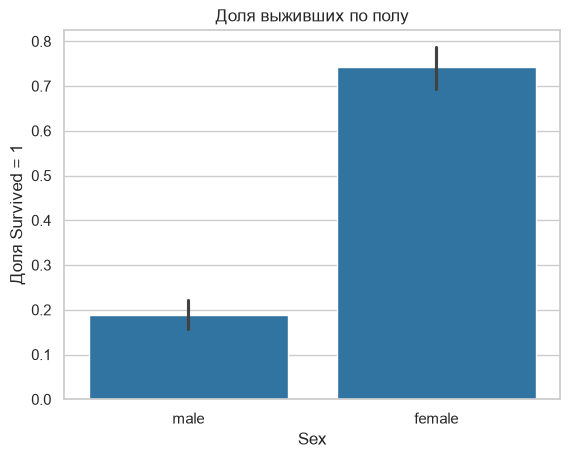

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [7]:
sns.barplot(data=train, x="Sex", y="Survived", color="tab:blue")
plt.title("Доля выживших по полу")
plt.ylabel("Доля Survived = 1")
plt.show()

train.groupby("Sex")["Survived"].mean()

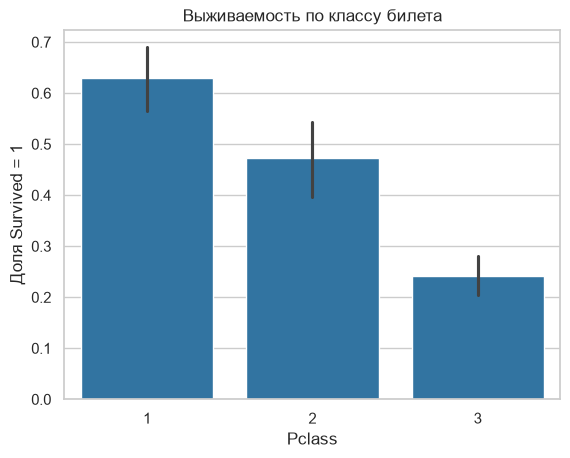

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [8]:
sns.barplot(data=train, x="Pclass", y="Survived", color="tab:blue")
plt.title('Выживаемость по классу билета')
plt.ylabel("Доля Survived = 1")
plt.show()
train.groupby("Pclass")["Survived"].mean()

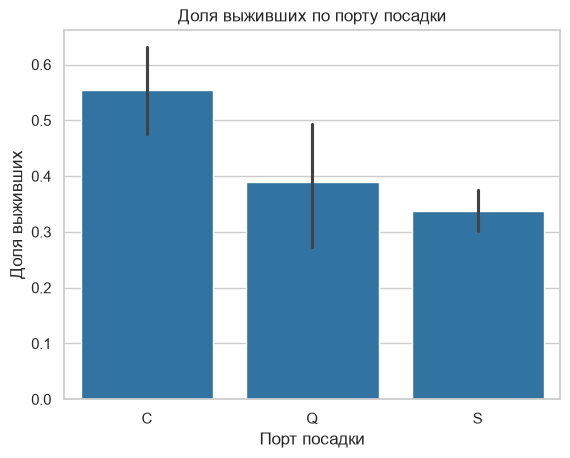

,survival_rate,passengers
Embarked,,
C,0.553571,168
Q,0.389610,77
S,0.336957,644
NaN,1.000000,2


In [9]:
sns.barplot(data=train, x="Embarked", y="Survived", order=["C", "Q", "S"], color="tab:blue")
plt.title("Доля выживших по порту посадки")
plt.xlabel("Порт посадки")
plt.ylabel("Доля выживших")
plt.show()

train.groupby("Embarked", dropna=False)["Survived"].agg(["mean", "count"]).rename(
    columns={"mean": "survival_rate", "count": "passengers"}
)

**Предварительное наблюдение:** в этих данных доля выживших заметно выше среди женщин и пассажиров первого класса. Это связь в конкретной выборке, а не доказательство причинности.

### 2.3. Возраст и цена билета

Посмотрим, различаются ли распределения `Age` и `Fare` у выживших и погибших. Для `Fare` дополнительно используем логарифмическую шкалу: несколько очень дорогих билетов растягивают обычную шкалу.

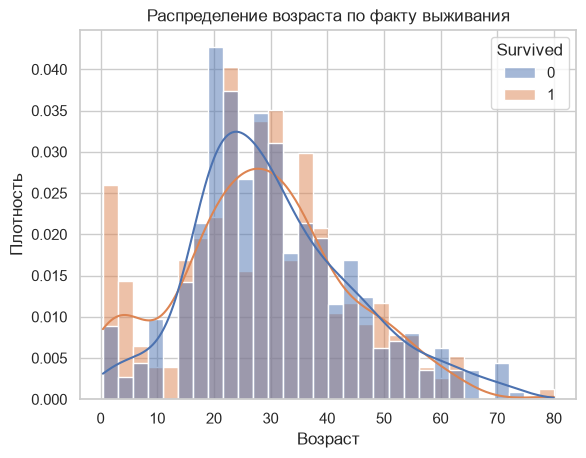

In [10]:
sns.histplot(
    data=train,
    x="Age",
    hue="Survived",
    kde=True,
    stat="density",
    common_norm=False,
    bins=30,
)
plt.title("Распределение возраста по факту выживания")
plt.xlabel("Возраст")
plt.ylabel("Плотность")
plt.show()

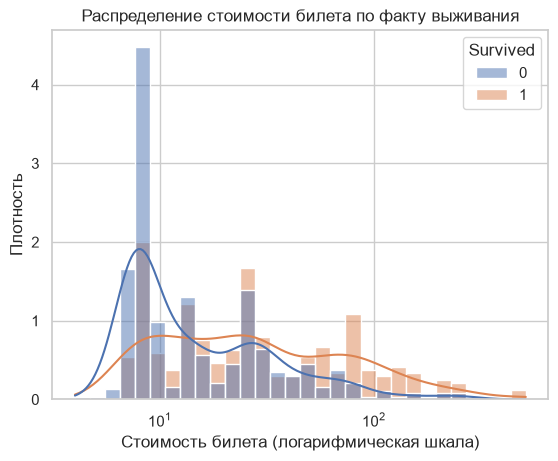

In [11]:
sns.histplot(
    data=train.loc[train["Fare"] > 0],
    x="Fare",
    hue="Survived",
    kde=True,
    stat="density",
    common_norm=False,
    log_scale=True,
    bins=30,
)
plt.title("Распределение стоимости билета по факту выживания")
plt.xlabel("Стоимость билета (логарифмическая шкала)")
plt.ylabel("Плотность")
plt.show()

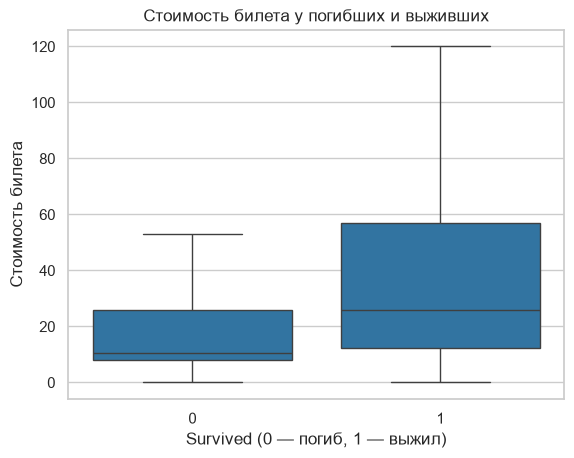

In [12]:
sns.boxplot(data=train, x="Survived", y="Fare", showfliers=False, color="tab:blue")
plt.title("Стоимость билета у погибших и выживших")
plt.xlabel("Survived (0 — погиб, 1 — выжил)")
plt.ylabel("Стоимость билета")
plt.show()

### 2.4. Семья и тепловая карта

`SibSp` и `Parch` удобнее смотреть как категории: доля выживших при разном количестве родственников. Обязательно смотрим и на количество пассажиров в каждой группе: значение для группы из двух человек нельзя считать таким же надёжным, как значение для группы из ста человек.

Тепловая карта показывает линейные корреляции числовых колонок. `PassengerId` исключим: это идентификатор, а не содержательный признак.

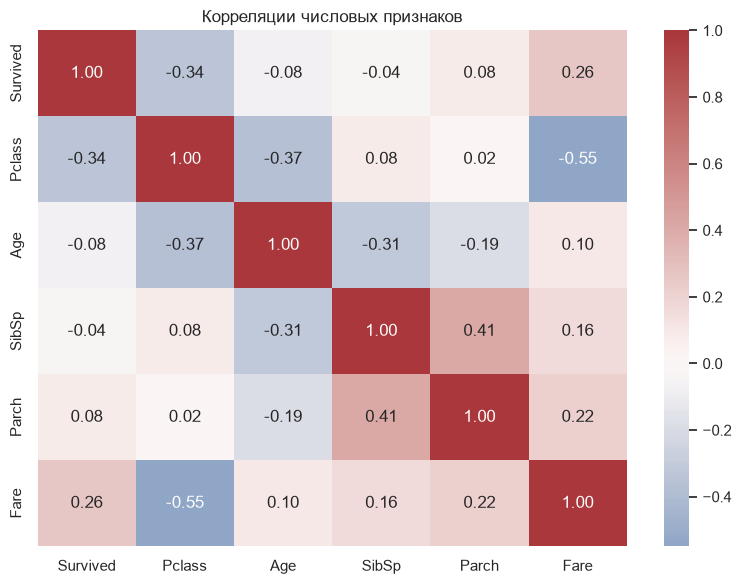

In [13]:
numeric_for_corr = train.drop(columns=["PassengerId"], errors="ignore").corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(numeric_for_corr, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Корреляции числовых признаков")
plt.tight_layout()
plt.show()

,survival_rate,passengers
SibSp,,
0,0.345395,608
1,0.535885,209
2,0.464286,28
3,0.250000,16
4,0.166667,18
5,0.000000,5
8,0.000000,7


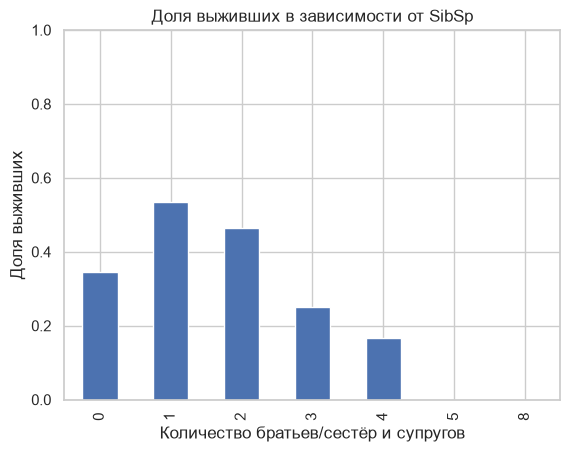

In [14]:
sibsp_stats = train.groupby("SibSp")["Survived"].agg(["mean", "count"])
sibsp_stats = sibsp_stats.rename(columns={"mean": "survival_rate", "count": "passengers"})

display(sibsp_stats)
sibsp_stats["survival_rate"].plot(kind="bar")
plt.title("Доля выживших в зависимости от SibSp")
plt.xlabel("Количество братьев/сестёр и супругов")
plt.ylabel("Доля выживших")
plt.ylim(0, 1)
plt.show()

,survival_rate,passengers
Parch,,
0,0.343658,678
1,0.550847,118
2,0.500000,80
3,0.600000,5
4,0.000000,4
5,0.200000,5
6,0.000000,1


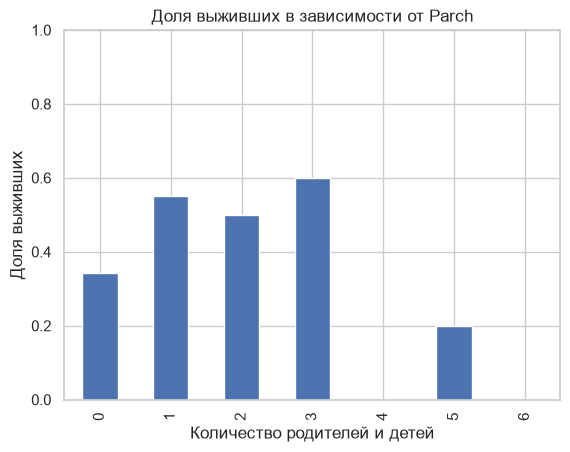

In [15]:
parch_stats = train.groupby("Parch")["Survived"].agg(["mean", "count"])
parch_stats = parch_stats.rename(columns={"mean": "survival_rate", "count": "passengers"})

display(parch_stats)
parch_stats["survival_rate"].plot(kind="bar")
plt.title("Доля выживших в зависимости от Parch")
plt.xlabel("Количество родителей и детей")
plt.ylabel("Доля выживших")
plt.ylim(0, 1)
plt.show()

**Промежуточный вывод:** по графикам видно, что пол и класс билета связаны с выживанием особенно заметно. По `Age`, `Fare`, `SibSp` и `Parch` нужно быть аккуратнее: форма распределения и размер каждой группы важны. Окончательно оценим полезность признаков на модели и с помощью SHAP.

## 3. Подготовка данных для моделей

Сначала создадим дополнительные признаки:

- `FamilySize = SibSp + Parch + 1` — размер семьи на борту.
- `IsAlone` — ехал ли пассажир один.
- `Title` — обращение, извлечённое из `Name`; редкие обращения объединим в `Rare`.

Сырые `Name`, `Ticket`, `Cabin` и `PassengerId` в модель не передаём.

Дальше используем `ColumnTransformer` и `Pipeline`:

- числовые пропуски заполняются медианой, числовые признаки масштабируются;
- категориальные пропуски заполняются самым частым значением, категории кодируются через `OneHotEncoder`;
- все шаги обучаются только на `X_train`. Это предотвращает утечку информации из validation.

Такой подход немного длиннее ручного `fillna` и `get_dummies`, зато одним и тем же способом подготавливает данные для всех моделей и для Kaggle test.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_features(data):
    """Создаёт признаки из исходных колонок train.csv или test.csv."""
    features = pd.DataFrame(index=data.index)

    # Числовые признаки.
    features["Pclass"] = data["Pclass"]
    features["Age"] = data["Age"]
    features["SibSp"] = data["SibSp"]
    features["Parch"] = data["Parch"]
    features["Fare"] = data["Fare"]
    features["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    features["IsAlone"] = (features["FamilySize"] == 1).astype(int)

    # Категориальные признаки.
    features["Sex"] = data["Sex"].fillna("Unknown")
    features["Embarked"] = data["Embarked"]

    # Извлекаем обращение из имени: "Braund, Mr. Owen Harris" -> "Mr".
    title = data["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    rare_titles = {
        "Dr", "Rev", "Col", "Major", "Capt", "Countess", "Lady",
        "Sir", "Don", "Dona", "Jonkheer"
    }
    title = title.where(~title.isin(rare_titles), "Rare")
    features["Title"] = title.fillna("Unknown")

    return features


X = make_features(train)
y = train["Survived"].astype(int)
X_test_final = make_features(test)

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone"]
categorical_features = ["Sex", "Embarked", "Title"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
    verbose_feature_names_out=False,
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("Пропуски до Pipeline в X_train:", int(X_train.isna().sum().sum()))
print("Признаки:", X.columns.tolist())

X_train: (712, 10)
X_valid: (179, 10)
Пропуски до Pipeline в X_train: 139
Признаки: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'Sex', 'Embarked', 'Title']


## 4. Обучение и сравнение моделей

Сравним шесть алгоритмов на одном и том же разбиении train/validation:

| Модель | Идея |
|---|---|
| Logistic Regression | Линейная граница между классами. |
| Decision Tree | Последовательность вопросов по признакам. Ограничим глубину, чтобы уменьшить переобучение. |
| Random Forest | Ансамбль деревьев, голосующих за класс. |
| XGBoost | Градиентный бустинг над деревьями. |
| CatBoost | Ещё один алгоритм градиентного бустинга. |
| KNN | Ищет ближайших пассажиров и использует их классы. Масштабирование уже включено в общий preprocessing. |

Дополнительно добавим `DummyClassifier`: он всегда предсказывает самый частый класс. Это baseline для accuracy.

Метрики:

- `accuracy` — доля правильных ответов;
- `f1` — баланс precision и recall для класса «выжил»;
- `roc_auc` — насколько хорошо модель ранжирует выживших выше погибших; здесь используются вероятности, а не классы.

Если `xgboost` или `catboost` не установлены, соответствующая модель будет пропущена. Установка: `pip install xgboost catboost shap`.

In [20]:
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier


def make_model_pipeline(estimator):
    return Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", estimator),
    ])


models = {
    "Dummy (majority)": make_model_pipeline(
        DummyClassifier(strategy="most_frequent")
    ),
    "Logistic Regression": make_model_pipeline(
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
    ),
    "Decision Tree": make_model_pipeline(
        DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=5,
            random_state=RANDOM_STATE,
        )
    ),
    "Random Forest": make_model_pipeline(
        RandomForestClassifier(
            n_estimators=400,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    ),
    "KNN": make_model_pipeline(
        KNeighborsClassifier(n_neighbors=11, weights="distance")
    ),
}

# Бустинги подключаем отдельно: в базовой среде этих библиотек может не быть.
try:
    from xgboost import XGBClassifier

    models["XGBoost"] = make_model_pipeline(
        XGBClassifier(
            n_estimators=400,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.9,
            colsample_bytree=0.9,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    )
except ImportError:
    print("XGBoost пропущен: установи пакет командой pip install xgboost")

try:
    from catboost import CatBoostClassifier

    class CatBoostSklearnAdapter(ClassifierMixin, BaseEstimator):
        """Небольшая обёртка для совместимости CatBoost со свежим sklearn."""

        def __init__(self, iterations=500, depth=4, learning_rate=0.03,
                     random_seed=RANDOM_STATE, verbose=0, thread_count=-1):
            self.iterations = iterations
            self.depth = depth
            self.learning_rate = learning_rate
            self.random_seed = random_seed
            self.verbose = verbose
            self.thread_count = thread_count

        def fit(self, X, y):
            self.model_ = CatBoostClassifier(
                iterations=self.iterations,
                depth=self.depth,
                learning_rate=self.learning_rate,
                loss_function="Logloss",
                random_seed=self.random_seed,
                verbose=self.verbose,
                thread_count=self.thread_count,
            )
            self.model_.fit(X, y)
            self.classes_ = self.model_.classes_
            return self

        def predict(self, X):
            return np.asarray(self.model_.predict(X)).astype(int).ravel()

        def predict_proba(self, X):
            return self.model_.predict_proba(X)

    models["CatBoost"] = make_model_pipeline(CatBoostSklearnAdapter())
except ImportError:
    print("CatBoost пропущен: установи пакет командой pip install catboost")


results = []
fitted_models = {}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_valid)
    probabilities = pipeline.predict_proba(X_valid)[:, 1]

    results.append({
        "model": name,
        "accuracy": accuracy_score(y_valid, predictions),
        "f1": f1_score(y_valid, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_valid, probabilities),
    })
    fitted_models[name] = pipeline

scores = pd.DataFrame(results).sort_values(
    by=["accuracy", "roc_auc"],
    ascending=False,
).reset_index(drop=True)

display(scores.round(4))

baseline_accuracy = scores.loc[
    scores["model"] == "Dummy (majority)", "accuracy"
].iloc[0]
print(f"Baseline accuracy (всегда предсказывать большинство): {baseline_accuracy:.3f}")

XGBoost пропущен: установи пакет командой pip install xgboost
CatBoost пропущен: установи пакет командой pip install catboost


,model,accuracy,f1,roc_auc
0,Logistic Regression,0.8547,0.8030,0.8794
1,Decision Tree,0.8268,0.7737,0.8596
2,Random Forest,0.8268,0.7597,0.8469
3,KNN,0.8212,0.7612,0.8543
4,Dummy (majority),0.6145,0.0000,0.5000


Baseline accuracy (всегда предсказывать большинство): 0.615


### 4.1. Как сравнивать результаты

Смотри не только на первую строку таблицы. Accuracy важна, потому что именно её использует соревнование Titanic на Kaggle. ROC-AUC и F1 помогают увидеть другие стороны качества.

Ниже автоматически выведем лидеров по accuracy и ROC-AUC. Затем сравним качество лучшей по accuracy модели на train и validation: большая разница может указывать на переобучение.

In [18]:
best_accuracy_name = scores.loc[scores["accuracy"].idxmax(), "model"]
best_auc_name = scores.loc[scores["roc_auc"].idxmax(), "model"]

print(f"Лидер по accuracy: {best_accuracy_name}")
print(f"Лидер по ROC-AUC: {best_auc_name}")
print(f"Accuracy baseline: {baseline_accuracy:.3f}")

best_accuracy_model = fitted_models[best_accuracy_name]
train_predictions = best_accuracy_model.predict(X_train)
valid_predictions = best_accuracy_model.predict(X_valid)

train_accuracy = accuracy_score(y_train, train_predictions)
valid_accuracy = accuracy_score(y_valid, valid_predictions)

print(f"\n{best_accuracy_name}:")
print(f"Accuracy на train:      {train_accuracy:.3f}")
print(f"Accuracy на validation: {valid_accuracy:.3f}")
print(f"Разница:                {train_accuracy - valid_accuracy:.3f}")

Лидер по accuracy: Logistic Regression
Лидер по ROC-AUC: Logistic Regression
Accuracy baseline: 0.615

Logistic Regression:
Accuracy на train:      0.829
Accuracy на validation: 0.855
Разница:                -0.026


## 5. SHAP: важность признаков

Метрики показывают качество модели в целом. SHAP помогает понять, какие признаки влияют на её предсказания.

Для первой версии возьмём лучшую по ROC-AUC модель из тех, которые основаны на деревьях: Decision Tree, Random Forest, XGBoost или CatBoost. К ней применим `shap.TreeExplainer`.

На beeswarm-графике каждая точка — пассажир. Положение по горизонтали показывает направление и силу вклада признака в предсказание класса «выжил»; цвет показывает значение признака.

In [19]:
import shap

# Выбираем лучшую по ROC-AUC модель среди моделей на деревьях.
tree_model_names = {"Decision Tree", "Random Forest", "XGBoost", "CatBoost"}
tree_scores = scores[scores["model"].isin(tree_model_names)]

if tree_scores.empty:
    raise RuntimeError("Нет доступной модели на деревьях для SHAP.")

best_tree_name = tree_scores.iloc[0]["model"]
best_tree_pipeline = fitted_models[best_tree_name]
tree_estimator = best_tree_pipeline.named_steps["model"]
if best_tree_name == "CatBoost":
    tree_estimator = tree_estimator.model_

# Преобразуем validation тем же preprocessing, который уже обучен на X_train.
X_valid_transformed = best_tree_pipeline.named_steps["preprocessor"].transform(X_valid)
feature_names = best_tree_pipeline.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(tree_estimator)
raw_shap_values = explainer.shap_values(X_valid_transformed)

# В зависимости от версии SHAP и модели результат может быть списком
# для двух классов или массивом с последней размерностью для классов.
if isinstance(raw_shap_values, list):
    shap_values_survived = raw_shap_values[1]
else:
    raw_shap_array = np.asarray(raw_shap_values)
    if raw_shap_array.ndim == 3:
        shap_values_survived = raw_shap_array[:, :, 1]
    else:
        shap_values_survived = raw_shap_array

print("Модель для SHAP:", best_tree_name)
print("Тип исходного результата:", type(raw_shap_values))
print("Форма SHAP для класса Survived=1:", shap_values_survived.shape)

shap.summary_plot(
    shap_values_survived,
    X_valid_transformed,
    feature_names=feature_names,
    show=False,
)
plt.title(f"SHAP summary — {best_tree_name}")
plt.tight_layout()
plt.show()

shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_values_survived).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

display(shap_importance.head(10).round(4))

ModuleNotFoundError: No module named 'shap'

### 5.1. Вывод по SHAP

Посмотри на первые три строки таблицы и сопоставь их с EDA. Важно: SHAP объясняет поведение конкретной обученной модели, а не доказывает причинно-следственную связь.

In [ ]:
top_3_features = shap_importance.head(3)["feature"].tolist()
print("Три наиболее важных признака по среднему абсолютному SHAP:")
for rank, feature in enumerate(top_3_features, start=1):
    print(f"{rank}. {feature}")

## 6. Короткий итог для себя

Три предложения, без новых графиков:

1. Что в данных сильнее всего связано с выживанием.
2. Какая модель лучшая на valid и чем она лучше «всегда говорить, что человек погиб».
3. Что бы ты поменял во второй итерации: глубина дерева, медиана возраста по классу, признак из `Name`, и так далее.

На GitHub по заданию нужен один репозиторий и папка `week1` с этим ноутбуком. Рядом положи `train.csv` (и `test.csv`, если он используется). Папку `.venv` в git не клади.

## 6. Итог проекта

В конце соберём основные результаты автоматически: лучший алгоритм по accuracy, его качество относительно baseline и три наиболее важных признака по SHAP.

In [ ]:
baseline_row = scores.loc[scores["model"] == "Dummy (majority)"].iloc[0]
best_row = scores.loc[scores["model"] == best_accuracy_name].iloc[0]

print("ИТОГ")
print(f"1. Лучшая модель по accuracy: {best_accuracy_name}.")
print(
    f"2. Её accuracy на validation: {best_row['accuracy']:.3f}; "
    f"baseline: {baseline_row['accuracy']:.3f}; "
    f"разница: {best_row['accuracy'] - baseline_row['accuracy']:+.3f}."
)
print(f"3. Топ-3 признака по SHAP для {best_tree_name}: {', '.join(top_3_features)}.")
print(
    "4. Следующий шаг для улучшения: проверить устойчивость метрик на StratifiedKFold, "
    "попробовать новые признаки (например, Deck из Cabin) и настроить гиперпараметры."
)

## 7. Kaggle submission

Для Kaggle требуется CSV с двумя колонками: `PassengerId` и `Survived`. Обучим модель, которая показала лучшую **accuracy на validation**, заново на всём `train.csv`, а затем предскажем ответы для `test.csv`.

Важно: у `test.csv` нет известных целевых значений, поэтому локально посчитать качество на нём нельзя. Итоговый файл можно загрузить в соревнование Titanic на Kaggle.

In [ ]:
from sklearn.base import clone

# Выбираем модель по метрике соревнования — accuracy на отложенной выборке.
final_model = clone(models[best_accuracy_name])
final_model.fit(X, y)

test_predictions = final_model.predict(X_test_final).astype(int)

submission = pd.DataFrame({
    "PassengerId": test["PassengerId"].astype(int),
    "Survived": test_predictions,
})

# Проверяем формат перед сохранением.
assert submission.columns.tolist() == ["PassengerId", "Survived"]
assert len(submission) == len(test)
assert submission["Survived"].isin([0, 1]).all()
assert submission.isna().sum().sum() == 0

submission_path = Path("submission.csv")
submission.to_csv(submission_path, index=False)

print(f"Файл сохранён: {submission_path.resolve()}")
print("Размер:", submission.shape)
display(submission.head(10))

## 8. Что положить в GitHub

Рекомендуемая структура:

```text
repository/
└── week1/
    ├── titanic_project_completed.ipynb
    ├── train.csv          # локальный файл датасета; проверь правила публикации данных
    ├── test.csv           # локальный файл датасета; проверь правила публикации данных
    └── submission.csv     # создаётся при запуске ноутбука
```

Папку `.venv` в Git не добавляй. Для воспроизводимости укажи зависимости в `requirements.txt`, например: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `xgboost`, `catboost`, `shap`, `jupyter`.